In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

learn = pd.read_csv("learn.csv", index_col=0)

<a id="sec-3-4-1"></a>
#### <font color='#097a6d'>**3.4.1 Hidden missing values: is 0 a real value or a placeholder?**</font>

In aviation accident records, a value of 0 is ambiguous and can have three different meanings:

- **A real measurement or a binary state:** a calm wind, a visibility of 0 miles in fog, an accident at the airport (0 miles) or a non-fatal accident.
- **A structural "none" or "not applicable":** no cloud ceiling, no gusts, or no engine in a glider.
- **A placeholder for something that was not recorded:** an altimeter setting of 0 or a pilot aged 0, where the zero is written instead of leaving the cell empty.

The first two kinds must be kept, since they carry information. The third kind is a hidden missing value and must be treated like the empty cells of section 3.4. Many of these cases were already decided in section 3.2, so this subsection does not repeat those analyses. It audits **every column** of `learn.csv`, cross-references the rules already established, and examines the zeros that 3.2 left open.

The code below only creates boolean masks and summary tables, so `learn` remains unchanged, as stated in section 1.2. It first counts the zeros of all columns (the number 0 in numeric columns and the text `"0"` in string columns). Then it assigns **every** zero to one case, with a verdict of real zero or placeholder, and checks that the cases add up to the raw count of each column. Features with both verdicts are classified as context-dependent. The first table summarises the result by feature.

In [ ]:
# Read-only audit: only masks and summary tables are created, learn is never modified.
# 1) Where does 0 (or the string "0") appear at all?
audit = []
for col in learn.columns:
    s = learn[col]
    if pd.api.types.is_numeric_dtype(s):
        n0, kind = int((s == 0).sum()), "numeric"
    else:
        n0, kind = int((s.astype("string").str.strip() == "0").sum()), "string"
    audit.append([col, kind, n0])

audit = pd.DataFrame(audit, columns=["Feature", "Type", "Zeros"])
print("Numeric columns:", (audit["Type"] == "numeric").sum(), "| with zeros:", ((audit["Type"] == "numeric") & (audit["Zeros"] > 0)).sum())
print("String columns :", (audit["Type"] == "string").sum(), "| with the value '0':", ((audit["Type"] == "string") & (audit["Zeros"] > 0)).sum())


# 2) Every zero is assigned to one case: (feature, case, mask, verdict, where the rule comes from)
def zero_cases(df, ifr_cutoff):
    """Returns the list of zero cases of a dataset. It only builds boolean masks."""
    cat = df["acft_category"].str.upper()
    sky = df["sky_cond_ceil"].str.upper()
    wx = df["wx_cond_basic"].str.upper()
    t, dew, alt = df["wx_temp"], df["wx_dew_pt"], df["altimeter"]
    wind, wdir, gust = df["wind_vel_kts"], df["wind_dir_deg"], df["gust_kts"]
    R, P = "Real", "Placeholder"

    cases = [
        ("wx_temp", "dew point also 0", (t == 0) & (dew == 0), P, "3.2.7"),
        ("wx_temp", "dew point above 0 (above the temperature)", (t == 0) & (dew > 0), P, "New"),
        ("wx_temp", "dew point below 0 (consistent)", (t == 0) & (dew < 0), R, "New"),
        ("wx_dew_pt", "temperature also 0", (dew == 0) & (t == 0), P, "3.2.7"),
        ("wx_dew_pt", "temperature above 40 °F", (dew == 0) & (t > 40), P, "New"),
        ("wx_dew_pt", "temperature 1 to 40 °F, altimeter 0", (dew == 0) & t.between(1, 40) & (alt == 0), P, "New"),
        ("wx_dew_pt", "temperature 1 to 40 °F, altimeter recorded", (dew == 0) & t.between(1, 40) & (alt != 0), R, "New"),
        ("wx_dew_pt", "temperature below 0 (dew point above it)", (dew == 0) & (t < 0), P, "3.2.7"),
        ("altimeter", "all zeros", alt == 0, P, "3.2.7"),
        ("wind_dir_deg", "wind speed missing", (wdir == 0) & wind.isna(), P, "3.2.8"),
        ("wind_dir_deg", "calm wind (speed 0)", (wdir == 0) & (wind == 0), R, "New"),
        ("wind_dir_deg", "wind speed above 0", (wdir == 0) & (wind > 0), P, "New"),
        ("wind_vel_kts", "calm wind (direction also 0)", (wind == 0), R, "New"),
        ("gust_kts", "wind speed recorded", (gust == 0) & wind.notna(), R, "3.2.8"),
        ("gust_kts", "wind speed missing", (gust == 0) & wind.isna(), P, "New"),
        ("sky_ceil_ht", "ceiling NONE", (df["sky_ceil_ht"] == 0) & (sky == "NONE"), R, "3.2.9"),
        ("sky_ceil_ht", "ceiling UNK or missing", (df["sky_ceil_ht"] == 0) & (sky.isna() | (sky == "UNK")), R, "New"),
        ("sky_ceil_ht", "ceiling BKN, OVC or VV", (df["sky_ceil_ht"] == 0) & sky.isin(["BKN", "OVC", "VV"]), P, "3.2.9"),
        ("vis_sm", "IMC", (df["vis_sm"] == 0) & (wx == "IMC"), R, "3.2.9"),
        ("vis_sm", "VMC or unknown", (df["vis_sm"] == 0) & (wx != "IMC"), R, "3.2.9"),
        ("apt_dist", "at the airport", df["apt_dist"] == 0, R, "New"),
        ("apt_elev", "sea level", df["apt_elev"] == 0, R, "New"),
        ("num_eng", "glider or balloon", (df["num_eng"] == 0) & cat.isin(["GLI", "BALL"]), R, "3.2.2"),
        ("num_eng", "other aircraft (airplanes)", (df["num_eng"] == 0) & ~cat.isin(["GLI", "BALL"]), P, "3.2.2"),
        ("eng_power", "engine present (num_eng > 0)", (df["eng_power"] == 0) & (df["num_eng"] > 0), P, "3.2.2"),
        ("eng_power", "number of engines missing", (df["eng_power"] == 0) & df["num_eng"].isna(), P, "New"),
        ("total_seats", "all zeros", df["total_seats"] == 0, P, "3.2.4"),
        ("pilot_age", "all zeros", df["pilot_age"] == 0, P, "3.2.5"),
        ("acft_year", "all zeros", df["acft_year"] == 0, P, "3.2.10"),
        ("ev_hour", "midnight (UTC)", df["ev_hour"] == 0, R, "3.2.6"),
        ("wx_temp_c", "32 °F (conversion)", df["wx_temp_c"] == 0, R, "3.2.7"),
        ("ifr_equipped_cert", f"year up to {ifr_cutoff} (flag not filled in)", (df["ifr_equipped_cert"] == 0) & (df["ev_year"] <= ifr_cutoff), P, "New"),
        ("ifr_equipped_cert", f"year after {ifr_cutoff}", (df["ifr_equipped_cert"] == 0) & (df["ev_year"] > ifr_cutoff), R, "New"),
    ]
    if "fatal" in df.columns:
        cases.append(("fatal", "non-fatal accident (target)", df["fatal"] == 0, R, "2.1.2"))
    return cases


# The IFR flag cut-off is computed from learn: years where fewer than 1 in 4 of the usual 1s appear
share_ones = learn.groupby("ev_year")["ifr_equipped_cert"].mean()
plateau = share_ones.iloc[-5:].mean()
IFR_CUTOFF = int(share_ones[share_ones < 0.25 * plateau].index.max())

case_table = pd.DataFrame(
    [[f, c, int(m.sum()), v, s] for f, c, m, v, s in zero_cases(learn, IFR_CUTOFF)],
    columns=["Feature", "Case", "Rows", "Verdict", "Rule from"])

# 3) Column level summary, checked against the raw zero count of the audit
summary = case_table.pivot_table(index="Feature", columns="Verdict", values="Rows", aggfunc="sum", fill_value=0)
summary = summary.reindex(columns=["Real", "Placeholder"], fill_value=0)
summary.insert(0, "Zeros", summary["Real"] + summary["Placeholder"])
summary = summary.join(audit.set_index("Feature")["Zeros"].rename("Raw count"))
assert (summary["Zeros"] == summary["Raw count"]).all(), "some zeros are not assigned to a case"
assert set(summary.index) == set(audit.loc[audit["Zeros"] > 0, "Feature"]), "a column with zeros is missing"

summary["% of rows"] = (summary["Zeros"] / len(learn) * 100).round(2)
summary["Class"] = np.select([summary["Placeholder"] == 0, summary["Real"] == 0],
                             ["Real zero", "Placeholder"], "Context-dependent")
summary = summary.drop(columns="Raw count").rename(columns={"Real": "Real zeros", "Placeholder": "Placeholders"})
summary = summary[["Zeros", "% of rows", "Real zeros", "Placeholders", "Class"]]
class_order = {"Real zero": 0, "Context-dependent": 1, "Placeholder": 2}
summary = summary.sort_values(["Class", "Zeros"], key=lambda c: c.map(class_order) if c.name == "Class" else -c)
display(summary)

Numeric columns: 21 | with zeros: 19
String columns : 20 | with the value '0': 0


,Zeros,% of rows,Real zeros,Placeholders,Class
Feature,,,,,
fatal,14090,82.98,14090,0,Real zero
apt_dist,13119,77.27,13119,0,Real zero
ev_hour,826,4.86,826,0,Real zero
wx_temp_c,62,0.37,62,0,Real zero
apt_elev,58,0.34,58,0,Real zero
wind_vel_kts,51,0.30,51,0,Real zero
vis_sm,39,0.23,39,0,Real zero
gust_kts,14358,84.56,10795,3563,Context-dependent
ifr_equipped_cert,14087,82.97,8059,6028,Context-dependent


Zeros appear in 19 of the 21 numeric columns (`ev_year` and `ev_month` have none), while none of the 20 string columns contains the text `"0"`. Codes such as `091` in `far_part` are labels, and the missing information of categorical columns is coded as `UNK`, `NR` or `NONE`, which was handled in section 3.3. The 19 features fall into three classes:

- **Real zeros (7 features):** `fatal`, `apt_dist`, `ev_hour`, `wx_temp_c`, `apt_elev`, `wind_vel_kts` and `vis_sm`.
- **Placeholders (5 features):** `altimeter`, `eng_power`, `total_seats`, `pilot_age` and `acft_year`.
- **Context-dependent zeros (7 features):** `gust_kts`, `ifr_equipped_cert`, `sky_ceil_ht`, `wind_dir_deg`, `wx_dew_pt`, `wx_temp` and `num_eng`. The same 0 is valid in some records and a placeholder or an inconsistency in others, so the next table gives the exact count of each sub-case.

In [ ]:
# Sub-cases of the context-dependent features (exact counts, learn only)
context_features = summary.index[summary["Class"] == "Context-dependent"]
display(case_table[case_table["Feature"].isin(context_features)]
        .set_index(["Feature", "Case"]).assign(**{"% of its zeros": lambda x: (x["Rows"] / summary["Zeros"].reindex(x.index.get_level_values(0)).values * 100).round(1)}))

Rows      Verdict Rule from  % of its zeros
Feature           Case                                                                                    
wx_temp           dew point also 0                              832  Placeholder     3.2.7            97.3
                  dew point above 0 (above the temperature)       9  Placeholder       New             1.1
                  dew point below 0 (consistent)                 14         Real       New             1.6
wx_dew_pt         temperature also 0                            832  Placeholder     3.2.7            50.8
                  temperature above 40 °F                       692  Placeholder       New            42.2
                  temperature 1 to 40 °F, altimeter 0            62  Placeholder       New             3.8
                  temperature 1 to 40 °F, altimeter recorded     46         Real       New             2.8
                  temperature below 0 (dew point above it)        7  Placeholder     3.2.7             0.4
wind_dir_deg      wind speed missing                           3543  Placeholder     3.2.8            80.8
                  calm wind (speed 0)                            51         Real       New             1.2
                  wind speed above 0                            793  Placeholder       New            18.1
gust_kts          wind speed recorded                         10795         Real     3.2.8            75.2
                  wind speed missing                           3563  Placeholder       New            24.8
sky_ceil_ht       ceiling NONE                                10641         Real     3.2.9            82.9
                  ceiling UNK or missing                       2079         Real       New            16.2
                  ceiling BKN, OVC or VV                        114  Placeholder     3.2.9             0.9
num_eng           glider or balloon                             241         Real     3.2.2            99.2
                  other aircraft (airplanes)                      2  Placeholder     3.2.2             0.8
ifr_equipped_cert year up to 2012 (flag not filled in)         6028  Placeholder       New            42.8
                  year after 2012                              8059         Real       New            57.2

#### <font color='#097a6d'>Real zeros, placeholders and context-dependent zeros</font>

**Real zeros.** In these features, 0 is a valid value and is kept.

- `fatal` is the target, and `apt_dist` = 0 means that the accident happened at the airport (13,119 records, 77%). Section 3.2.1 only treats distances above 1,000 miles as missing.
- `wind_vel_kts` = 0 is a calm wind: all 51 records also have a wind direction of 0.
- `vis_sm` = 0 corresponds to fog or very low cloud: 38 of the 39 records are in IMC, 31 have a broken, overcast or obscured sky, and the median ceiling is only 194 ft. The single VMC record is kept, as decided in 3.2.9, because we cannot know which of the two columns is wrong.
- `apt_elev` = 0 was not resolved in 3.2.10, which only removed impossible elevations. The 58 zeros do not form a spike: each elevation between 5 and 10 ft has 53 records on average, they appear in every year from 2009 to 2023, and 44 of them are at the airport, so they are compatible with sea-level airports.
- `ev_hour` = 0 is midnight in UTC, and `wx_temp_c` = 0 is a temperature of 32 °F. Both features are dropped in 3.2.6 and 3.2.7, so their zeros are irrelevant for NB1.

**Placeholders.** In these features, every 0 is impossible, so all of them become missing values: 1,510 in `altimeter` (3.2.7), 37 in `total_seats` (3.2.4), 4 in `pilot_age` (3.2.5) and 1 in `acft_year` (3.2.10). In `eng_power` all 171 zeros are placeholders: 170 belong to aircraft with an engine (3.2.2) and the last one to an airplane with an unknown number of engines. No glider or balloon has a power of 0, since they have either no value or a positive one.

**Context-dependent zeros.** The table of sub-cases shows where the previous sections already decided the case ("Rule from" = section) and where the rule is new. The new evidence is gathered in the table below.

- **Temperature and dew point.** Section 3.2.7 sets both to missing when both are 0 (832 records). Of the 23 other records with a temperature of 0, 14 have a dew point between -12 and -2 °F and occur from November to February, so they are real freezing temperatures. The other 9 have a dew point above the temperature, and 8 of them are between March and September with dew points from 24 to 71 °F, so the zero is the placeholder. For the dew point, 3.2.7 only suspected that the 692 zeros with a temperature above 40 °F were placeholders. Even among records with a recorded altimeter, they are 229 against 12 neighbours, and their fatal rate is 4.2% against 17% overall. When the temperature is between 1 and 40 °F, a dew point of 0 is plausible, except when the altimeter is also 0 (62 records), since a dew point of 0 appears in 86% of the records with an altimeter of 0 and in only 2.2% of the records with a normal altimeter. The remaining 46 are kept.
- **Wind direction and gusts.** Besides the 3,543 zeros with a missing wind speed (3.2.8) and the 51 calm winds, another 793 records have a direction of 0 with a wind above 0. Zero is not a heading (north is 360, which appears in only 35 records) and these winds are weaker (28.8% are at most 3 kts, against 9.2%), which is typical of variable winds with no defined direction. When the wind speed is missing, 98.9% of the gusts are 0 against 80.7% when it is recorded, so those 3,563 zeros cannot be told apart from gusts that were not measured. The remaining 10,795 are kept, in line with the `has_gust` variable of 3.2.8.
- **Cloud ceiling.** Of the 12,834 zeros, 10,641 have `sky_cond_ceil` = NONE (no ceiling) and 114 have a broken, overcast or obscured sky (3.2.9). The other 2,079 have an unknown or missing condition. Only 0.9% of the records with an unknown condition have a ceiling above 0, against 27.7% of the others, which means that a ceiling is almost always reported when it exists. These zeros therefore mean "no ceiling" and are kept.
- **Number of engines.** The 241 gliders and balloons without an engine are real, while the 2 airplanes with 0 engines are impossible (3.2.2).
- **IFR certification.** `ifr_equipped_cert` is a binary flag, where 0 means "not certified", but its share of 1s depends strongly on the year. It is practically 0% until 2010 and only reaches a stable 25% to 32% after 2015. Among the flights with an IFR flight plan, 98.7% have a 0 up to 2011, against 18.9% from 2015, so in the first years the flag was not filled in and the zero is a default value. The cut-off is computed in the code as the last year where the share of 1s is below a quarter of its recent level (2012). After it, the flag was filled in gradually, and the zeros of 2013 and 2014 mix both situations. Even later, 27.6% of the Part 121 flights, which are airliners, have a 0, so some later zeros may also be unrecorded. They cannot be identified one by one, so they are kept.

In [ ]:
# Evidence behind the new rules (learn only)
t, dew, alt = learn["wx_temp"], learn["wx_dew_pt"], learn["altimeter"]
wind, wdir, gust = learn["wind_vel_kts"], learn["wind_dir_deg"], learn["gust_kts"]
sky = learn["sky_cond_ceil"].str.upper()
ceil, elev = learn["sky_ceil_ht"], learn["apt_elev"]
ev = []

# dew point: isolated spike in rows with a normal observation
ok = learn[(t > 40) & alt.between(27, 32)]["wx_dew_pt"]
ev.append(["wx_dew_pt = 0 (temperature > 40 °F, altimeter recorded)", f"{(ok == 0).sum()} rows",
           f"{(ok.between(-2, 2) & (ok != 0)).sum()} rows with dew point from -2 to 2 (without 0)", "Isolated spike"])

# wind direction: 0 is not a heading, north is 360
spd = learn[(wdir >= 0) & (wind > 0)]["wind_dir_deg"]
ev.append(["wind_dir_deg = 0 with wind speed > 0", f"{(spd == 0).sum()} rows",
           f"{(spd == 360).sum()} rows at 360 (north), and at most {spd[spd > 0].value_counts().max()} rows for any other value", "Not a valid heading"])
dir0, dirok = (wdir == 0) & (wind > 0), (wdir > 0) & (wind > 0)
ev.append(["Wind speed <= 3 kts", f"{(wind[dir0] <= 3).mean():.1%} of the rows with direction 0 and wind",
           f"{(wind[dirok] <= 3).mean():.1%} of the rows with a valid direction", "Looks like variable winds"])

# gusts: 0 is only informative when the wind itself was recorded
ev.append(["gust_kts = 0 when the wind speed is missing", f"{(gust[wind.isna()] == 0).mean():.1%} of those rows",
           f"{(gust[wind.notna()] == 0).mean():.1%} when it is recorded", "Gusts cannot be observed without wind"])

# ceiling: with a ceiling condition UNK/missing, almost never a height above 0
unk = sky.isna() | (sky == "UNK")
ev.append(["sky_ceil_ht > 0 when sky_cond_ceil is UNK or missing", f"{(ceil[unk] > 0).mean():.1%} of {unk.sum()} rows",
           f"{(ceil[~unk] > 0).mean():.1%} of the other rows", "Ceilings are reported when they exist"])

# elevation 0 continues the distribution of low airports
ev.append(["apt_elev = 0", f"{(elev == 0).sum()} rows",
           f"{elev[elev.between(5, 10)].value_counts().mean():.0f} rows on average for each elevation from 5 to 10 ft", "No spike"])

# visibility 0
v0 = learn[learn["vis_sm"] == 0]
ev.append(["vis_sm = 0", f"{len(v0)} rows, {v0['sky_cond_ceil'].str.upper().isin(['BKN', 'OVC', 'VV']).sum()} with BKN, OVC or VV",
           f"median ceiling {v0['sky_ceil_ht'].median():.0f} ft, fatal rate {v0['fatal'].mean():.1%}", "Fog or low cloud"])

# IFR flag: share of 1s per year
ones = learn.groupby("ev_year")["ifr_equipped_cert"].mean() * 100
ev.append(["ifr_equipped_cert = 1, by year", " | ".join(f"{y}: {v:.0f}%" for y, v in ones.items() if y <= 2014),
           f"{ones.iloc[-9:].min():.0f}% to {ones.iloc[-9:].max():.0f}% from 2015 to 2023", "Flag filled in gradually"])

pd.set_option("display.max_colwidth", None)
display(pd.DataFrame(ev, columns=["Check", "Observed", "Reference", "Reading"]).set_index("Check"))

,Observed,Reference,Reading
Check,,,
"wx_dew_pt = 0 (temperature > 40 °F, altimeter recorded)",229 rows,12 rows with dew point from -2 to 2 (without 0),Isolated spike
wind_dir_deg = 0 with wind speed > 0,793 rows,"35 rows at 360 (north), and at most 62 rows for any other value",Not a valid heading
Wind speed <= 3 kts,28.8% of the rows with direction 0 and wind,9.2% of the rows with a valid direction,Looks like variable winds
gust_kts = 0 when the wind speed is missing,98.9% of those rows,80.7% when it is recorded,Gusts cannot be observed without wind
sky_ceil_ht > 0 when sky_cond_ceil is UNK or missing,0.9% of 2097 rows,27.7% of the other rows,Ceilings are reported when they exist
apt_elev = 0,58 rows,53 rows on average for each elevation from 5 to 10 ft,No spike
vis_sm = 0,"39 rows, 31 with BKN, OVC or VV","median ceiling 194 ft, fatal rate 64.1%",Fog or low cloud
"ifr_equipped_cert = 1, by year",2008: 0% | 2009: 0% | 2010: 0% | 2011: 1% | 2012: 4% | 2013: 12% | 2014: 20%,25% to 32% from 2015 to 2023,Flag filled in gradually


The new rules are supported by the same type of evidence in every case: a spike or a share that does not follow the neighbouring values (`wx_dew_pt`, `wind_dir_deg`), a zero that cannot be observed because the underlying measurement is missing (`gust_kts`), or a value that continues the distribution (`apt_elev`, `sky_ceil_ht`, `vis_sm`). Taken together, the placeholders add up to 18,200 cells to be converted into missing values. Most are in `ifr_equipped_cert` (6,028), `wind_dir_deg` (4,336), `gust_kts` (3,563) and `wx_dew_pt` (1,593), and many of the weather ones occur in the accidents with no weather observation, which are also much less fatal (see 3.2.7).

The chart below summarises the split of the zeros of each feature, after resolving the sub-cases. The target and the two dropped features (`ev_hour` and `wx_temp_c`) are left out.

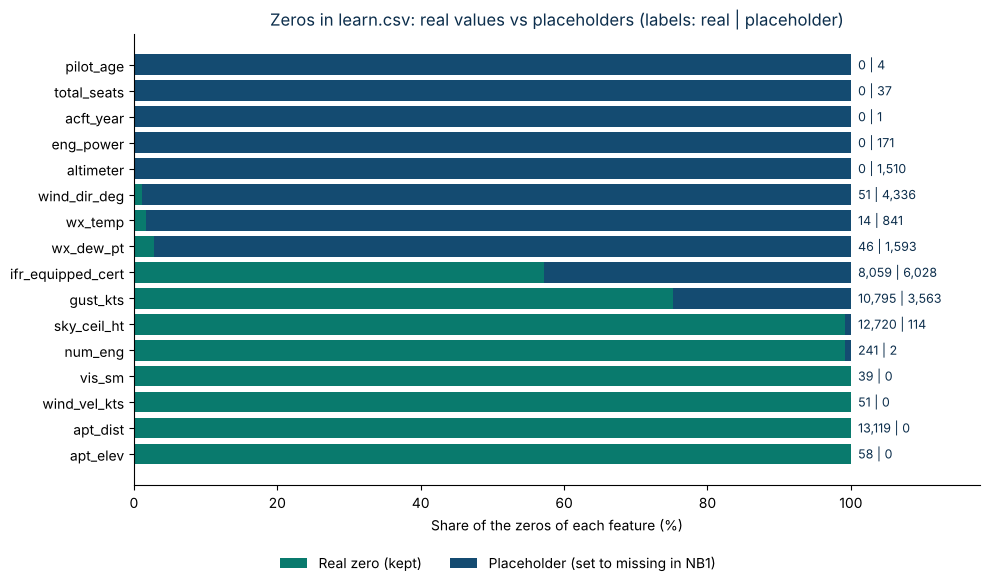

In [ ]:
# Real zeros vs placeholders in the affected features (target and dropped features are left out)
fig_data = (case_table[~case_table["Feature"].isin(["fatal", "ev_hour", "wx_temp_c"])]
            .pivot_table(index="Feature", columns="Verdict", values="Rows", aggfunc="sum", fill_value=0)
            .reindex(columns=["Real", "Placeholder"], fill_value=0))
fig_data["share"] = fig_data["Placeholder"] / fig_data.sum(axis=1) * 100
fig_data = fig_data.sort_values("share")

fig, ax = plt.subplots(figsize=(10, 6))
real_pct = 100 - fig_data["share"]
ax.barh(fig_data.index, real_pct, color="#097a6d", label="Real zero (kept)")
ax.barh(fig_data.index, fig_data["share"], left=real_pct, color="#144b71", label="Placeholder (set to missing in NB1)")

for i, (feature, row) in enumerate(fig_data.iterrows()):
    ax.text(101, i, f"{int(row['Real']):,} | {int(row['Placeholder']):,}", va="center", fontsize=9, color="#0c2e4c")

ax.set_xlim(0, 118)
ax.set_xticks(range(0, 101, 20))
ax.set_xlabel("Share of the zeros of each feature (%)")
ax.set_title("Zeros in learn.csv: real values vs placeholders (labels: real | placeholder)", color="#0c2e4c")
ax.legend(loc="lower center", bbox_to_anchor=(0.43, -0.22), ncol=2, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

The features fall into three groups. At the top, `pilot_age`, `total_seats`, `acft_year`, `eng_power` and `altimeter` have only placeholders, and `wind_dir_deg`, `wx_temp` and `wx_dew_pt` are almost entirely placeholders, with only a few valid zeros. In the middle, `ifr_equipped_cert` and `gust_kts` are split between both kinds, while `sky_ceil_ht` and `num_eng` have very few placeholders. At the bottom, `vis_sm`, `wind_vel_kts`, `apt_dist` and `apt_elev` contain only real zeros.

<div style="background-color:#061b2e; padding:20px; border-radius:10px; color:#FFFFFF;">
  <b>DECISION FOR NB1</b>
</div>

**Order of application.** The zeros listed below as placeholders are converted into missing values on the raw data, before any imputation, and they receive the same missing indicator as the empty cells. The derived features (`at_airport`, `has_gust`, `has_ceiling`) are built from the raw values before the imputation. All rules use only the values of each record (and a fixed year), so they do not depend on the target or on the rest of the dataset.

**Rules inherited from section 3.2 (consolidated, unchanged):**

- `altimeter` = 0 becomes missing (3.2.7), and a `no_weather` indicator will be tested.
- `wx_temp` and `wx_dew_pt` become missing when both are 0 (832 records), and a dew point above the temperature also becomes missing (3.2.7). This includes the 7 records with a dew point of 0 and a negative temperature. `wx_temp_c` is dropped.
- `wind_dir_deg` = 0 with a missing `wind_vel_kts` becomes missing (3,543 records, 3.2.8).
- `has_gust` is built from `gust_kts` > 0 (3.2.8).
- `sky_ceil_ht` = 0 with a `BKN`, `OVC` or `VV` sky becomes missing (114 records, 3.2.9).
- `vis_sm` = 0 is kept, including the VMC record (3.2.9).
- `total_seats` = 0 (37 records, 3.2.4), `pilot_age` = 0 (4 records, 3.2.5) and `acft_year` = 0 (1 record, 3.2.10) become missing.
- `eng_power` = 0 with an engine becomes missing (170 records), and `num_eng` = 0 in the 2 airplanes becomes missing (3.2.2).
- `num_eng` = 0 in gliders and balloons (241 records) is kept.
- `apt_dist` = 0 is kept, since only values above 1,000 miles are errors (3.2.1), and `ev_hour` is dropped (3.2.6).

**New rules added in 3.4.1:**

- `wx_temp` = 0 with a dew point above 0 becomes missing (9 records), while `wx_temp` = 0 with a negative dew point is kept (14 records).
- `wx_dew_pt` = 0 becomes missing when the temperature is above 40 °F (692 records), and when the temperature is between 1 and 40 °F and the altimeter is 0 (62 records). The other 46 zeros are kept.
- `wind_dir_deg` = 0 with a wind speed above 0 becomes missing (793 records). The 51 calm winds are kept, together with `wind_vel_kts` = 0.
- `gust_kts` = 0 becomes missing when `wind_vel_kts` is missing (3,563 records), and `has_gust` is missing in the same records. The 10,795 zeros with a recorded wind are kept.
- `sky_ceil_ht` = 0 is kept when `sky_cond_ceil` is `NONE`, `UNK` or missing (12,720 records). `has_ceiling` is 1 when the height is above 0, 0 when it is 0 and kept as a real value, and missing when the height is missing.
- `eng_power` = 0 with a missing `num_eng` becomes missing (1 record), so all 171 zeros of `eng_power` become missing.
- `ifr_equipped_cert` = 0 becomes missing up to 2012 (6,028 records) and is kept from 2013 onwards (8,059 records).
- `apt_elev` = 0 (58 records), `vis_sm` = 0 (39 records) and the target `fatal` = 0 are kept, and `at_airport` (from `apt_dist` = 0) is created.
- The string columns have no zeros, so they need no rule.

**Effect on the imputation.** Since the median of `gust_kts` and `ifr_equipped_cert` is 0, the converted zeros are filled with 0 again after the imputation. For these two features, the practical gain of the rules is the missing indicator, which keeps the information that the value was not recorded.

**General rules for the missing values of 3.4 (unchanged):**

- No rows or columns will be removed because of missing values. Even `acft_year` (40%) and `apt_elev` (34%) still have values for most accidents, and removing rows would mean losing a large part of the data. Since the target `fatal` is complete, no accident has to be removed because of it either.
- All missing values will be filled in NB1, including the columns with only a few (`acft_make`, `far_part`, `phase`).
- Numerical features will be filled with the median, which is less affected by the extreme values found earlier. The median will be computed on the training data only.
- Since the fatal rate changes when some values are missing (for example, `second_pilot`, `vis_sm` and `apt_elev`), we will add an indicator for each numerical feature with missing values (1 if missing, 0 otherwise), so this information is not lost.
- For categorical features, the missing values will become a separate category (`MISSING`) instead of being replaced by the most frequent one.
- Since the weather placeholders have a much lower fatal rate (between 4% and 7%), their missing indicators may be useful for the model.